# 01 · Paper results: SD / pooled / SI

**Purpose.** Trains the locked ~25K-parameter TOPO-FM TD-CNN under the three evaluation regimes (subject-dependent, pooled, subject-independent LOSO) on the official BCIC2020 Track 3 train → validation split, and reports balanced accuracy, Cohen's kappa and weighted F1.

**Produces.** Table 1 (regime comparison). The figure at the end is a working plot; the paper's Fig. 6 is drawn by `03_make_figures.ipynb`.

**Inputs.** BCIC2020 Track 3 `.mat` files (`$BCIC_DATA`, else the Kaggle input, else `./data`), with `Train/*.mat` and `valid/*.mat`.

**Outputs** (in `$RESULTS_DIR/paper`, default `./results/paper` or `/kaggle/working/paper`): `maps.pkl` (map cache, not committed), `predictions.npz`, `per_subject_metrics.csv`, `regime_summary.csv`, `comparison.csv`, `figure_regimes.png`.

**Run order.** Run first. `02` reuses `maps.pkl`; `03` reads `predictions.npz` and the CSVs. If `predictions.npz` already exists in the output folder, training is skipped and the tables are recomputed from it; point `RESULTS_DIR` at an empty folder to retrain.

# Paper results — SD / SI / Pooled with literature-matched metrics
Emits **Balanced Accuracy / Cohen's kappa / Weighted F1** (the BCIC2020-3 convention) for all three
regimes, saves per-subject predictions, and builds the regime-tagged comparison table + figure.

**Locked config (a-priori, not test-selected):** `l2=1e-4, sd=0.2, do=0.4` (C0). `WSTRIDE=3`.
Masked 1-channel mean-voltage TOPO-FM maps + Flatten TD-CNN + temporal avg-pool (~25K params).

**Regime tags for the comparison (verified from the literature):**
- **SD (per-subject):** each subject its own model. Matches Jeong et al. deep-metric-learning (48.1%).
- **Pooled (subject-mixed):** one model, all subjects, test trials from *seen* subjects. Matches the
  foundation-model benchmark numbers (EEGNet 44.1 ... CBraMod 53.7 ... CSBrain 60.0), which use
  5-seed std and pretraining — a *different, easier* regime than SD.
- **SI (LOSO):** held-out subject, zero-shot. Chance for everyone (CBraMod/LaBraM at chance per NeuroTTT).

Runs the three regimes once (checkpointed), caches predictions, then recomputes tables/figure instantly on rerun.

In [1]:
import numpy as np, scipy.io, glob, os, time, gc, json, pickle
import pandas as pd
from scipy.interpolate import griddata
from scipy.spatial import cKDTree
from sklearn.metrics import balanced_accuracy_score, cohen_kappa_score, f1_score, accuracy_score
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical
for g in tf.config.list_physical_devices('GPU'): tf.config.experimental.set_memory_growth(g,True)
print('TF',tf.__version__,'| GPUs',len(tf.config.list_physical_devices('GPU')))

TF 2.20.0 | GPUs 2


In [2]:
# Config — LOCKED
NUM_CLASSES=5; FS=256; MAP=32; WSTRIDE=3
CFG=dict(l2=1e-4, sd=0.2, do=0.4)   # a-priori config, not test-selected
classNames=['Hello','Help me','Stop','Thank you','Yes']
label_to_channel={
    'Fp1':0,'Fp2':1,'F7':2,'F3':3,'Fz':4,'F4':5,'F8':6,'FC5':7,'FC1':8,'FC2':9,'FC6':10,
    'T7':11,'C3':12,'Cz':13,'C4':14,'T8':15,'TP9':16,'CP5':17,'CP1':18,'CP2':19,'CP6':20,
    'TP10':21,'P7':22,'P3':23,'Pz':24,'P4':25,'P8':26,'PO9':27,'O1':28,'Oz':29,'O2':30,
    'PO10':31,'AF7':32,'AF3':33,'AF4':34,'AF8':35,'F5':36,'F1':37,'F2':38,'F6':39,'FT9':40,
    'FT7':41,'FC3':42,'FC4':43,'FT8':44,'FT10':45,'C5':46,'C1':47,'C2':48,'C6':49,'TP7':50,
    'CP3':51,'CPz':52,'CP4':53,'TP8':54,'P5':55,'P1':56,'P2':57,'P6':58,'PO7':59,'PO3':60,
    'POz':61,'PO4':62,'PO8':63}
selected=list(label_to_channel.keys()); sel_idx=np.array([label_to_channel[c] for c in selected])
# Paths: BCIC_DATA / RESULTS_DIR environment variables override the Kaggle defaults;
# off Kaggle they fall back to ./data and ./results at the repository root.
_ROOT=os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd())=='notebooks' else os.getcwd()
ON_KAGGLE=os.path.exists('/kaggle/working')
RESULTS_DIR=os.environ.get('RESULTS_DIR') or ('/kaggle/working' if ON_KAGGLE else os.path.join(_ROOT,'results'))
DATA_ROOT=os.environ.get('BCIC_DATA')
if DATA_ROOT is None:
    for path in ['/kaggle/input/datasets/sanaephd/imu-shah-2024-dataset',
                 '/kaggle/input/imu-shah-2024-dataset','/kaggle/input/imu-shah-2024']+                ([f'/kaggle/input/{d}' for d in os.listdir('/kaggle/input')
                  if ('imu' in d.lower() or 'shah' in d.lower())] if os.path.exists('/kaggle/input') else [])+                [os.path.join(_ROOT,'data')]:
        if os.path.exists(os.path.join(path,'Train')) and os.path.exists(os.path.join(path,'valid')):
            DATA_ROOT=path; break
train_files=sorted(glob.glob(os.path.join(DATA_ROOT,'Train','*.mat')))
valid_files=sorted(glob.glob(os.path.join(DATA_ROOT,'valid','*.mat')))
OUT=os.path.join(RESULTS_DIR,'paper'); os.makedirs(OUT,exist_ok=True)
CACHE=f'{OUT}/maps.pkl'; PRED=f'{OUT}/predictions.npz'
print('dataset:',DATA_ROOT,'|',len(train_files),'subjects')

dataset: /kaggle/input/datasets/sanaephd/imu-shah-2024-dataset | 15 subjects


In [3]:
# mask + 1-channel masked mean-voltage maps
def _todict(o):
    d={}
    for f in o._fieldnames:
        e=o.__dict__[f]; d[f]=_todict(e) if isinstance(e,scipy.io.matlab.mat_struct) else e
    return d
def _check(d):
    for k in d:
        if isinstance(d[k],scipy.io.matlab.mat_struct): d[k]=_todict(d[k])
    return d
mnt0=_check(scipy.io.loadmat(train_files[0],struct_as_record=False,squeeze_me=True))['mnt']
x_sel,y_sel=mnt0['x'][sel_idx],mnt0['y'][sel_idx]
xi,yi=np.meshgrid(np.linspace(x_sel.min(),x_sel.max(),MAP),np.linspace(y_sel.min(),y_sel.max(),MAP))
tree=cKDTree(np.c_[x_sel,y_sel]); d1,_=tree.query(np.c_[xi.ravel(),yi.ravel()],k=1)
dd,_=tree.query(np.c_[x_sel,y_sel],k=2); MASK=(d1.reshape(MAP,MAP)<=1.2*np.median(dd[:,1]))

def build_maps(file, win_ms=125, overlap=50, start_map=6, end_map=44, wstride=WSTRIDE):
    md=_check(scipy.io.loadmat(file,struct_as_record=False,squeeze_me=True))
    epo=next(md[k] for k in ['epo_train','epo_test','epo_validation','epo'] if k in md)
    data=epo['x']; y=np.argmax(epo['y'],axis=0)
    win=round(FS*win_ms/1000); ov=round(win*overlap/100); step=win-ov
    total=data.shape[0]; n_maps=int(np.floor((total-ov)/step)); n_trials=data.shape[2]
    filt=data.copy()
    for t in range(n_trials):
        tr=filt[:,:,t]; filt[:,:,t]=tr-tr.mean(axis=1,keepdims=True)
    wins=[w for w in range(n_maps) if (start_map-1<=w<end_map) and ((w-(start_map-1))%wstride==0)]
    out=np.zeros((n_trials,len(wins),MAP,MAP,1),dtype=np.float32)
    for t in range(n_trials):
        dt=filt[:,sel_idx,t]
        for wi,w in enumerate(wins):
            s=w*step; e=s+win; v=dt[s:e,:].mean(0)
            zi=griddata((x_sel,y_sel),v,(xi,yi),method='cubic'); zi=np.where(MASK,zi,np.nan)
            if np.isfinite(zi).any():
                lo,hi=np.nanmin(zi),np.nanmax(zi); zn=(zi-lo)/(hi-lo) if hi>lo else np.zeros_like(zi)
            else: zn=np.zeros_like(zi)
            zn=np.nan_to_num(zn); zn[~MASK]=0.0; out[t,wi,:,:,0]=zn
    return out, y

if os.path.exists(CACHE):
    with open(CACHE,'rb') as f: subj=pickle.load(f)
    print('loaded maps from cache')
else:
    t0=time.time(); subj=[]
    for i,(tf_,vf_) in enumerate(zip(train_files,valid_files)):
        Xtr,ytr=build_maps(tf_); Xte,yte=build_maps(vf_)
        subj.append(dict(id=i,name=os.path.basename(tf_).replace('.mat',''),Xtr=Xtr,ytr=ytr,Xte=Xte,yte=yte))
        print(f'[{i+1:2d}/15] built')
    with open(CACHE,'wb') as f: pickle.dump(subj,f)
    print(f'built+cached in {time.time()-t0:.0f}s')
INP=subj[0]['Xtr'].shape[1:]; print('input',INP)

/tmp/ipykernel_23/2680725329.py:9: DeprecationWarning: Please import `mat_struct` from the `scipy.io.matlab` namespace; the `scipy.io.matlab.mio5_params` namespace is deprecated and will be removed in SciPy 2.0.0.
  if isinstance(d[k],scipy.io.matlab.mio5_params.mat_struct): d[k]=_todict(d[k])
/tmp/ipykernel_23/2680725329.py:5: DeprecationWarning: Please import `mat_struct` from the `scipy.io.matlab` namespace; the `scipy.io.matlab.mio5_params` namespace is deprecated and will be removed in SciPy 2.0.0.
  e=o.__dict__[f]; d[f]=_todict(e) if isinstance(e,scipy.io.matlab.mio5_params.mat_struct) else e


[ 1/15] built
[ 2/15] built
[ 3/15] built
[ 4/15] built
[ 5/15] built
[ 6/15] built
[ 7/15] built
[ 8/15] built
[ 9/15] built
[10/15] built
[11/15] built
[12/15] built
[13/15] built
[14/15] built
[15/15] built
built+cached in 134s
input (13, 32, 32, 1)


In [4]:
# Model (locked C0) + helpers
def build_model(input_shape=INP,n_classes=NUM_CLASSES,w1=32,w2=64,wb=16,l2=CFG['l2'],sd=CFG['sd'],do=CFG['do'],lr=1e-3):
    reg=regularizers.l2(l2); inp=layers.Input(shape=input_shape)
    x=layers.TimeDistributed(layers.Conv2D(w1,3,padding='same',activation='relu',kernel_regularizer=reg))(inp)
    x=layers.TimeDistributed(layers.BatchNormalization())(x)
    x=layers.TimeDistributed(layers.MaxPooling2D(2))(x)
    x=layers.TimeDistributed(layers.SpatialDropout2D(sd))(x)
    x=layers.TimeDistributed(layers.Conv2D(w2,3,padding='same',activation='relu',kernel_regularizer=reg))(x)
    x=layers.TimeDistributed(layers.BatchNormalization())(x)
    x=layers.TimeDistributed(layers.MaxPooling2D(2))(x)
    x=layers.TimeDistributed(layers.SpatialDropout2D(sd))(x)
    x=layers.TimeDistributed(layers.Conv2D(wb,1,padding='same',activation='relu',kernel_regularizer=reg))(x)
    x=layers.TimeDistributed(layers.Flatten())(x)
    x=layers.GlobalAveragePooling1D()(x)
    x=layers.Dropout(do)(x)
    out=layers.Dense(n_classes,activation='softmax',kernel_regularizer=reg)(x)
    m=models.Model(inp,out); m.compile(optimizer=optimizers.Adam(lr),loss='categorical_crossentropy',metrics=['accuracy'])
    return m

def strat_val(y,val_frac=0.15,seed=0):
    rng=np.random.RandomState(seed); tr=[]; va=[]
    for c in range(NUM_CLASSES):
        ci=np.where(y==c)[0]; rng.shuffle(ci); k=max(1,int(len(ci)*val_frac)); va+=list(ci[:k]); tr+=list(ci[k:])
    return np.array(tr),np.array(va)

def fit(Xtr,ytr,seed=0,epochs=80,batch=32):
    tr,va=strat_val(ytr,0.15,seed); m=build_model()
    m.fit(Xtr[tr],to_categorical(ytr[tr],NUM_CLASSES),
          validation_data=(Xtr[va],to_categorical(ytr[va],NUM_CLASSES)),
          epochs=epochs,batch_size=batch,verbose=0,
          callbacks=[EarlyStopping('val_loss',patience=15,restore_best_weights=True,verbose=0),
                     ReduceLROnPlateau('val_loss',factor=0.5,patience=6,min_lr=1e-6,verbose=0)])
    return m
def predict(m,X): return np.argmax(m.predict(X,verbose=0),axis=1)
print('params:', f'{build_model().count_params():,}')

I0000 00:00:1783511276.146261      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1783511276.149030      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


params: 25,365


## Train 3 regimes, save per-subject predictions (checkpointed)

In [5]:
if os.path.exists(PRED):
    Z=np.load(PRED,allow_pickle=True); preds={k:Z[k].item() for k in ['sd','si','pooled']}; ytrue={s['id']:s['yte'] for s in subj}
    print('loaded cached predictions')
else:
    preds={'sd':{}, 'si':{}, 'pooled':{}}; ytrue={s['id']:s['yte'] for s in subj}
    # SD: per-subject
    for s in subj:
        m=fit(s['Xtr'],s['ytr'],seed=s['id']); preds['sd'][s['id']]=predict(m,s['Xte'])
        print(f"SD  {s['name']}: {accuracy_score(s['yte'],preds['sd'][s['id']])*100:.1f}%")
        del m; keras.backend.clear_session(); gc.collect()
    # SI: leave-one-subject-out, zero-shot
    for s in subj:
        Xtr=np.concatenate([o['Xtr'] for o in subj if o['id']!=s['id']]); ytr=np.concatenate([o['ytr'] for o in subj if o['id']!=s['id']])
        m=fit(Xtr,ytr,seed=100+s['id']); preds['si'][s['id']]=predict(m,s['Xte'])
        print(f"SI  {s['name']}: {accuracy_score(s['yte'],preds['si'][s['id']])*100:.1f}%")
        del m,Xtr,ytr; keras.backend.clear_session(); gc.collect()
    # Pooled: one model, eval each subject's held-out valid
    Xtr=np.concatenate([s['Xtr'] for s in subj]); ytr=np.concatenate([s['ytr'] for s in subj])
    m=fit(Xtr,ytr,seed=7)
    for s in subj: preds['pooled'][s['id']]=predict(m,s['Xte'])
    print('Pooled done'); del m,Xtr,ytr; keras.backend.clear_session(); gc.collect()
    np.savez(PRED, sd=preds['sd'], si=preds['si'], pooled=preds['pooled'])
    print('predictions cached ->',PRED)

I0000 00:00:1783511319.590090      72 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


SD  Data_Sample01: 54.0%
SD  Data_Sample02: 24.0%
SD  Data_Sample03: 38.0%
SD  Data_Sample04: 60.0%
SD  Data_Sample05: 60.0%
SD  Data_Sample06: 30.0%
SD  Data_Sample07: 56.0%
SD  Data_Sample08: 56.0%
SD  Data_Sample09: 32.0%
SD  Data_Sample10: 56.0%
SD  Data_Sample11: 62.0%
SD  Data_Sample12: 58.0%
SD  Data_Sample13: 32.0%
SD  Data_Sample14: 58.0%
SD  Data_Sample15: 70.0%
SI  Data_Sample01: 24.0%
SI  Data_Sample02: 18.0%
SI  Data_Sample03: 16.0%
SI  Data_Sample04: 28.0%
SI  Data_Sample05: 30.0%
SI  Data_Sample06: 20.0%
SI  Data_Sample07: 32.0%
SI  Data_Sample08: 24.0%
SI  Data_Sample09: 14.0%
SI  Data_Sample10: 20.0%
SI  Data_Sample11: 26.0%
SI  Data_Sample12: 26.0%
SI  Data_Sample13: 18.0%
SI  Data_Sample14: 28.0%
SI  Data_Sample15: 14.0%
Pooled done
predictions cached -> /kaggle/working/paper/predictions.npz


## Metrics — Balanced Accuracy / Cohen's kappa / Weighted F1 (per subject + mean)

In [6]:
def M(yt,yp):
    return dict(bal_acc=balanced_accuracy_score(yt,yp)*100,
                kappa=cohen_kappa_score(yt,yp),
                wf1=f1_score(yt,yp,average='weighted')*100)
rows=[]
for s in subj:
    for reg in ['sd','si','pooled']:
        mm=M(ytrue[s['id']],preds[reg][s['id']]); mm.update(subject=s['name'],regime=reg); rows.append(mm)
R=pd.DataFrame(rows)
summary=R.groupby('regime').agg(bal_acc_m=('bal_acc','mean'),bal_acc_s=('bal_acc','std'),
                                kappa_m=('kappa','mean'),kappa_s=('kappa','std'),
                                wf1_m=('wf1','mean'),wf1_s=('wf1','std')).round(3)
order=['sd','si','pooled']; summary=summary.loc[order]
print('OUR RESULTS (mean +/- std over 15 subjects):')
for reg in order:
    r=summary.loc[reg]
    print(f"  {reg.upper():7s} Bal.Acc {r.bal_acc_m:5.2f}+/-{r.bal_acc_s:4.2f} | "
          f"kappa {r.kappa_m:.3f}+/-{r.kappa_s:.3f} | W-F1 {r.wf1_m:5.2f}+/-{r.wf1_s:4.2f}")
R.round(3).to_csv(f'{OUT}/per_subject_metrics.csv',index=False)
summary.to_csv(f'{OUT}/regime_summary.csv')

OUR RESULTS (mean +/- std over 15 subjects):
  SD      Bal.Acc 49.73+/-14.30 | kappa 0.372+/-0.179 | W-F1 48.77+/-14.71
  SI      Bal.Acc 22.53+/-5.83 | kappa 0.032+/-0.073 | W-F1 20.91+/-5.76
  POOLED  Bal.Acc 41.07+/-9.59 | kappa 0.263+/-0.120 | W-F1 40.39+/-9.71


## Regime-tagged comparison with the literature

In [7]:
# Literature values for BCIC2020-3 (5-class). Bal.Acc in %.
# Sources: CBraMod (arXiv:2412.07236) benchmark table; CSBrain (2506.23075); CoMET (2509.00314);
# BrainPro (2509.22050); Jeong et al. deep metric learning (PubMed 34255630, 5-class 48.10);
# NeuroTTT (2509.26301): CBraMod/LaBraM at chance cross-subject.
lit=pd.DataFrame([
 ('Jeong et al. (deep metric learning)','SD (per-subject)','-',48.10),
 ('EEGNet','Pooled (mixed)','0.003M',44.13),
 ('EEGConformer','Pooled (mixed)','0.55M',45.06),
 ('FFCL','Pooled (mixed)','2.4M',46.78),
 ('BIOT','Pooled (mixed)','3.2M',49.20),
 ('LaBraM-Base','Pooled (mixed, pretrained)','5.8M',50.60),
 ('BrainPro','Pooled (mixed, pretrained)','-',52.53),
 ('CBraMod','Pooled (mixed, pretrained)','-',53.73),
 ('CoMET-Large','Pooled (mixed, pretrained)','-',55.72),
 ('CSBrain','Pooled (mixed, pretrained)','-',60.04),
 ('CBraMod / LaBraM (cross-subject)','SI (LOSO)','5.8M','chance'),
],columns=['method','regime','params','bal_acc'])
ours=pd.DataFrame([
 ('OURS: TOPO-FM TD-CNN','SD (per-subject)','~0.025M',round(summary.loc['sd','bal_acc_m'],2)),
 ('OURS: TOPO-FM TD-CNN','Pooled (mixed)','~0.025M',round(summary.loc['pooled','bal_acc_m'],2)),
 ('OURS: TOPO-FM TD-CNN','SI (LOSO)','~0.025M',round(summary.loc['si','bal_acc_m'],2)),
],columns=['method','regime','params','bal_acc'])
comp=pd.concat([lit,ours],ignore_index=True)
for reg in ['SD (per-subject)','Pooled (mixed)','Pooled (mixed, pretrained)','SI (LOSO)']:
    print(f'\n=== {reg} ===')
    print(comp[comp.regime==reg][['method','params','bal_acc']].to_string(index=False))
comp.to_csv(f'{OUT}/comparison.csv',index=False)


=== SD (per-subject) ===
                             method  params bal_acc
Jeong et al. (deep metric learning)       -    48.1
               OURS: TOPO-FM TD-CNN ~0.025M   49.73

=== Pooled (mixed) ===
              method  params bal_acc
              EEGNet  0.003M   44.13
        EEGConformer   0.55M   45.06
                FFCL    2.4M   46.78
                BIOT    3.2M    49.2
OURS: TOPO-FM TD-CNN ~0.025M   41.07

=== Pooled (mixed, pretrained) ===
     method params bal_acc
LaBraM-Base   5.8M    50.6
   BrainPro      -   52.53
    CBraMod      -   53.73
CoMET-Large      -   55.72
    CSBrain      -   60.04

=== SI (LOSO) ===
                          method  params bal_acc
CBraMod / LaBraM (cross-subject)    5.8M  chance
            OURS: TOPO-FM TD-CNN ~0.025M   22.53


## Figure

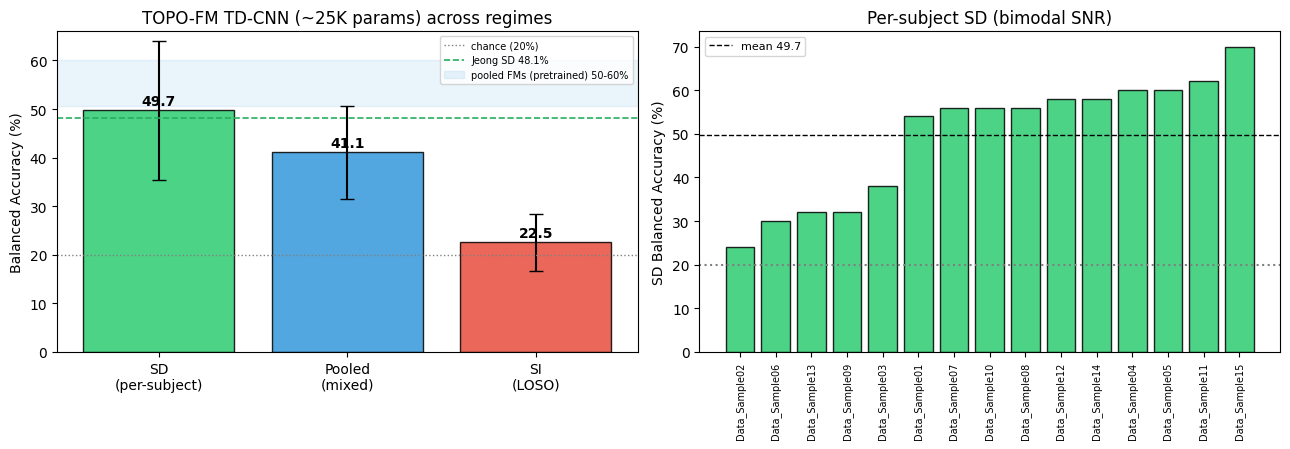

saved /kaggle/working/paper/figure_regimes.png


In [8]:
fig,ax=plt.subplots(1,2,figsize=(13,4.6))
# A: our three regimes with literature reference bands
means=[summary.loc['sd','bal_acc_m'],summary.loc['pooled','bal_acc_m'],summary.loc['si','bal_acc_m']]
stds =[summary.loc['sd','bal_acc_s'],summary.loc['pooled','bal_acc_s'],summary.loc['si','bal_acc_s']]
labs=['SD\n(per-subject)','Pooled\n(mixed)','SI\n(LOSO)']; cols=['#2ecc71','#3498db','#e74c3c']
b=ax[0].bar(labs,means,yerr=stds,capsize=5,color=cols,alpha=.85,edgecolor='k')
ax[0].axhline(20,ls=':',c='gray',lw=1,label='chance (20%)')
ax[0].axhline(48.1,ls='--',c='#27ae60',lw=1.2,label='Jeong SD 48.1%')
ax[0].axhspan(50.6,60.0,color='#3498db',alpha=.10,label='pooled FMs (pretrained) 50-60%')
for r,mv in zip(b,means): ax[0].text(r.get_x()+r.get_width()/2,mv+1.2,f'{mv:.1f}',ha='center',fontweight='bold')
ax[0].set_ylabel('Balanced Accuracy (%)'); ax[0].set_ylim(0,66)
ax[0].set_title('TOPO-FM TD-CNN (~25K params) across regimes'); ax[0].legend(fontsize=7,loc='upper right')
# B: per-subject SD sorted
sd=R[R.regime=='sd'].sort_values('bal_acc')
ax[1].bar(range(15),sd['bal_acc'],color='#2ecc71',alpha=.85,edgecolor='k')
ax[1].axhline(20,ls=':',c='gray'); ax[1].axhline(sd['bal_acc'].mean(),ls='--',c='k',lw=1,label=f'mean {sd.bal_acc.mean():.1f}')
ax[1].set_xticks(range(15)); ax[1].set_xticklabels(sd['subject'],rotation=90,fontsize=7)
ax[1].set_ylabel('SD Balanced Accuracy (%)'); ax[1].set_title('Per-subject SD'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT}/figure_regimes.png',dpi=200,bbox_inches='tight'); plt.show()
print('saved',f'{OUT}/figure_regimes.png')

## Paper-ready reads
- **SD (per-subject) vs Jeong 48.1%** — same regime, ~25K params, no pretraining. Clean comparison point.
- **Pooled < SD** — pooling subjects *hurts* without pretraining; imagined speech is subject-specific.
- **Pooled (mixed) vs foundation models 50-60%** — different, easier regime (pretraining + seen test
  subjects); report as context, not a head-to-head loss.
- **SI near chance** (22.5%; not significantly above chance across subjects, Wilcoxon p = 0.10), corroborated by NeuroTTT (CBraMod/LaBraM also at chance cross-subject). Cite your
  calibration paper as the route across the SD-SI gap.

Metrics saved: `per_subject_metrics.csv`, `regime_summary.csv`, `comparison.csv`, `figure_regimes.png`.
**Note:** confirm CBraMod/LaBraM pool subjects on BCIC2020-3 from their code before finalizing the
regime tags — the 5-seed std strongly implies it, but code-level confirmation makes the table airtight.